# **Icepack tutorial: Synthetic ice sheet**

Run an idealised experiment simulating the evolution of an ice sheet on millenial timescales. The bedrock topography will stay constant and will not include erosion.  

Starting with a rough guess of ice thickness, we'll solve the *diagnostic equation* for the velocity throughout. We'll then solve the *prognostic equation* to obtain ice thickness at a later time. We can solve these equations by assuming a given rate of accumulation and melting until the system is close to a steady state.  

1) Define the shape of the ice sheet and get a triangulation of the interior.
2) Define the initial guess for the ice thickness and velocity, and set a value of the rheology and accumulation rate.
3) Set the total simulation time and the number of time steps, and then iteratively update the ice thickness and velocity at each time step.

## **Geometry**  
The model domain is a circle 250 km wide, but with a 1 km-high ridge at a radius of 200 km. The ridge is punctuated by four valleys from which ice streams form.  
We use a different built-in function to create a circular mesh:

In [3]:
import firedrake

mesh = firedrake.UnitDiskMesh(5)
R = 250e3
mesh.coordinates.dat.data[:] *= R

We previously used matplotlib to create figure and axis objects. Now, we use a wrapper function in icepack that equalises the aspect ratio of plots and sets the axis labelling to work better for domains that are usually on the scale of hundreds of km.

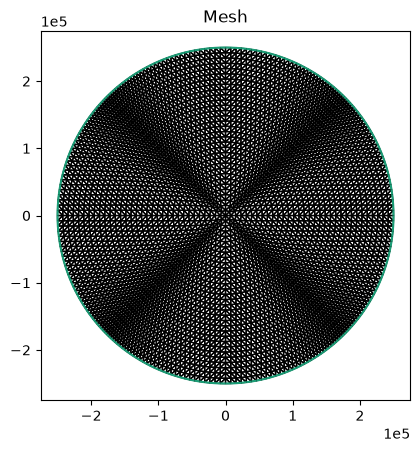

In [4]:
import icepack.plot

fig, axes = icepack.plot.subplots()
firedrake.triplot(mesh, axes=axes)
axes.set_title("Mesh");

## **Input data**  
Define expressions for the ice bed, surface, thickness, velocity, and accumulation rate. Then interpolate these expressions to function spaces.  
Function space for scalar fields (elevation, ice thickness, etc) = Q  
Function space for vector fields (velocity, etc) = V

In [5]:
Q = firedrake.FunctionSpace(mesh, family="CG", degree=2)
V = firedrake.VectorFunctionSpace(mesh, family="CG", degree=2)

To build up an expression for the bed topography, we'll use the bump and ramp functions that we used in the earlier tutorial.  
The expression for the bed topography is complex and messy. First, define some variables and functions:

In [6]:
from firedrake import sqrt, exp, Constant, Function

x, y = firedrake.SpatialCoordinate(mesh)
r = sqrt(x**2 + y**2)

# Plateau elevation
b_base = Constant(400)

# Max elevation
b_max = Constant(1400)

# Radius of the plateau interior
ro = 125e3

# Radius of the ridge
Ro = Constant(200e3)

def tanh(z):
    return (exp(z) - exp(-z)) / (exp(z) + exp(-z))

def θ(z):
    return (tanh(z) + 1) / 2

def sech(z):
    return 2 / (exp(z) + exp(-z))

Next, make the plateau on which the ice sheet will sit:

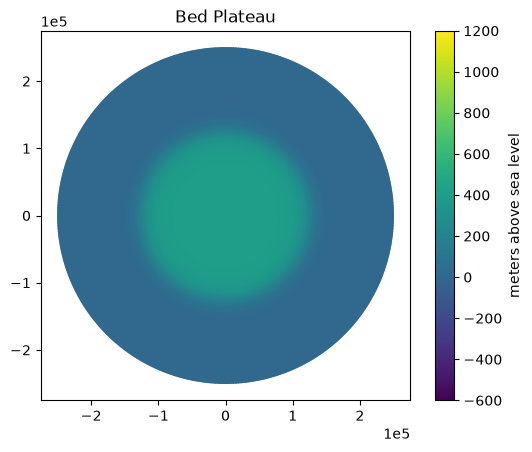

In [7]:
import numpy as np

a = Constant(50e3)
ξ = (sqrt(x**2 + y**2) - ro) / a

b_expr_plateau = b_base * (1 - θ(3 * ξ))
b = Function(Q).interpolate(b_expr_plateau)

fig, axes = icepack.plot.subplots()
kw = {"vmin": -600, "vmax": +1200}
colors = firedrake.tripcolor(b, axes=axes, **kw)
fig.colorbar(colors, label="meters above sea level")
axes.set_title("Bed Plateau");

Next, add a ridge that runs along the edge of the plateau:

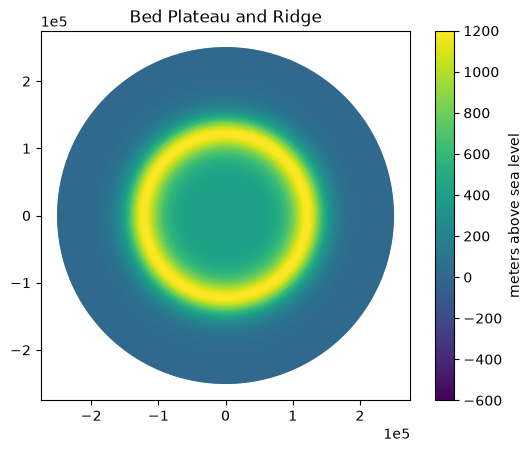

In [8]:
ζ = (r - Ro) / Ro
b_expr_ridge = (b_max - b_base) * sech(3 * ξ)
b_expr = b_expr_plateau + b_expr_ridge
b = Function(Q).interpolate(b_expr)

fig, axes = icepack.plot.subplots()
contours = firedrake.tripcolor(b, axes=axes, **kw)
fig.colorbar(contours, label="meters above sea level")
axes.set_title("Bed Plateau and Ridge");

Finally, cut valleys into the ridge to get bed topography:

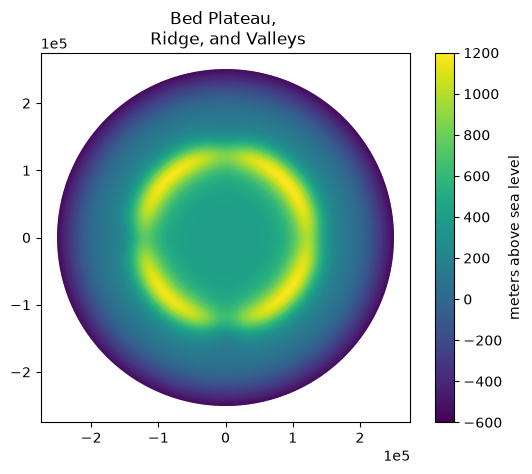

In [9]:
ρ1 = Constant(1 / 4)
μ1 = 1 - ρ1 * θ(3 * (x - ro / 4) / a) * sech(2 * y / a)

ρ2 = Constant(3 / 8)
μ2 = 1 - ρ2 * θ(3 * (y - ro / 4) / a) * sech(2 * x / a)

ρ3 = Constant(1 / 2)
μ3 = 1 - ρ3 * θ(3 * (-x + ro / 4) / a) * sech(2 * y / a)

ρ4 = Constant(5 / 8)
μ4 = 1 - ρ4 * θ(3 * (-y + ro / 4) / a) * sech(2 * x / a)

μ = μ1 * μ2 * μ3 * μ4

S = 480 / (1 - Ro / R)

b_expr_valleys = (b_max - b_base) * sech(3 * ξ) * μ - θ(5 * ζ) * S * ζ
b_expr = b_expr_plateau + b_expr_valleys
b = Function(Q).interpolate(b_expr)

fig, axes = icepack.plot.subplots()
contours = firedrake.tripcolor(b, axes=axes, **kw)
fig.colorbar(contours, label="meters above sea level")
axes.set_title("Bed Plateau, \n Ridge, and Valleys");

Now put an ice sheet on the bed. Starts as a half sphere, a starting point from which to evolve the ice sheet:

In [10]:
from firedrake import max_value

# Surface elevation
max_radius = 195e3
dome_height = 2.4e3
dome = dome_height * max_value(1 - (x**2 + y**2) / max_radius**2, 0)
s0 = Function(Q).interpolate(dome)

# Thickness
h0 = Function(Q).interpolate(max_value(s0 - b, 0))

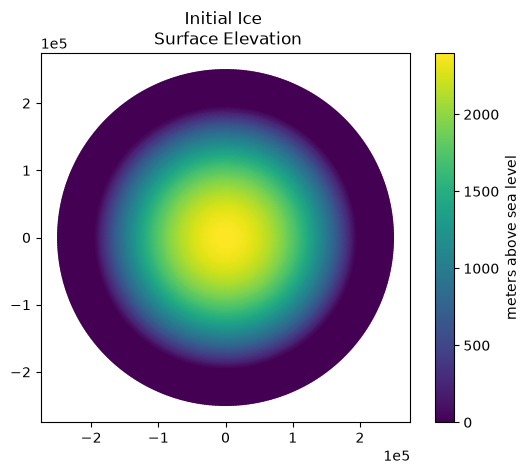

In [11]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(s0, axes=axes)
fig.colorbar(colors, label="meters above sea level")
axes.set_title("Initial Ice \n Surface Elevation"); 

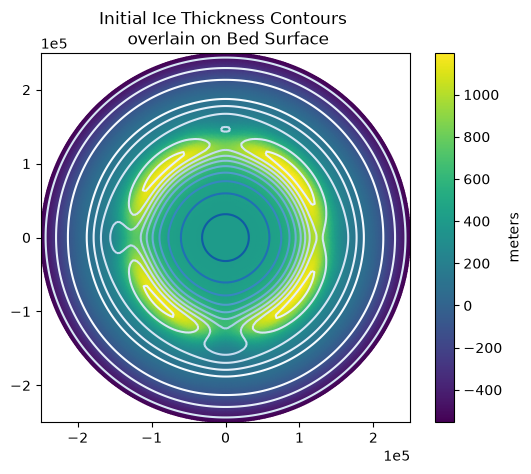

In [12]:
fig, axes = icepack.plot.subplots()
colors_b = firedrake.tripcolor(b, axes=axes)
levels = np.linspace(100, 2300, 13)
contours_h = firedrake.tricontour(h0, levels, axes=axes, cmap="Blues")
fig.colorbar(colors_b, label="meters")
axes.set_title("Initial Ice Thickness Contours \n overlain on Bed Surface");


## **Modelling**  
To start solving things, we need to make two objects.  
First, the class *ShallowIce* represents the physics problem we plan to solve. This class define the equations for the shallow ice approximation, applicable to parts of ice sheets and glaciers where ice flows slowly and there is little to no sliding. 

In [13]:
import icepack
model = icepack.models.ShallowIce()

Second, *FlowSolver* decides how we're going to solve the problem. When we initialise the flow solver we pass it any arguments that never change throughout a simulation. For this simulation, there are no arguments to pass.  
  
The main job of the flow solver object is to solve the PDEs for ice velocity and thickness, for which it has two methods: *diagnostic_solve* and *prognostic_solve*.

In [14]:
solver = icepack.solvers.FlowSolver(model)

We need one more input variable - the 'fluidity factor', *A*, in Glens flow law. *A* depends on several variables, especially temperature, *T*. For this exercise, we use a spatially constant *T* of -5 degrees. The code assumes all temperatures are in Kelvin.

In [15]:
T = Constant(273.15 - 5)
A = icepack.rate_factor(T)

To compute the velocity field, we call the diagnostic solve method of the ice sheet object. This method takes in thickness, surface elevation, *A*, and the initial guess for ice velocity. In this case, we have no initial guess. 

In [16]:
u0 = firedrake.Function(V)
h = h0.copy(deepcopy=True)
u = solver.diagnostic_solve(
    velocity=u0,
    thickness=h,
    surface=s0,
    fluidity=A,
)

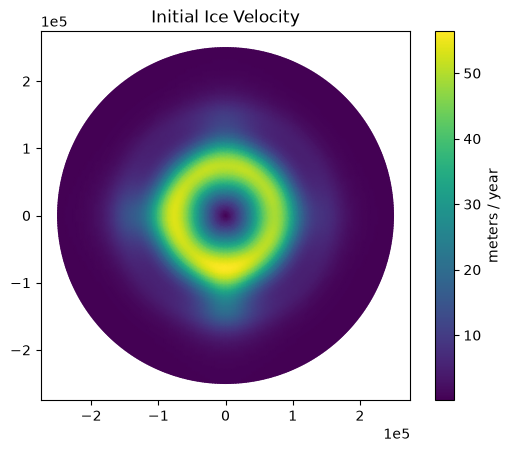

In [17]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(u, axes=axes)
fig.colorbar(colors, label="meters / year")
axes.set_title("Initial Ice Velocity");

To evolve the ice sheet, we need to choose a mass balance field. Here, we use a mass balance that is zero everywhere.

In [18]:
from firedrake import min_value

def mass_balance(s, max_a=0.5, da_ds=0.5/1000, ela=300.0):
    return min_value((s - ela) * da_ds, max_a)

ela = 300.
max_a = 0.
da_ds = 0.

a = mass_balance(s0, ela=ela, max_a=max_a, da_ds=da_ds)

To project the state of the ice sheet forward in time, we 1) call the *prognostic solve* routine to update ice thickness for one timestep given the accumulation rate and velocity, and 2) call the diagnostic solve routine to update the velocity given the current thickness.  

The following code runs 500 years with a 10-year time step until the ice sheet is roughly in steady state. We'll save the information about how much the thickness changes with time to later assess how close the ice sheet is to steady state.

In [20]:
from tqdm.notebook import trange

dt = 10
num_timesteps = 50

dh_max = np.zeros(num_timesteps) * np.nan
a = Function(Q)

for step in trange(num_timesteps):
    h_old = h.copy(deepcopy=True)
    h = solver.prognostic_solve(
        dt,
        thickness=h,
        accumulation=a,
        velocity=u,
    )

    h.interpolate(max_value(h, 0))
    s = Function(Q).interpolate(h + b)
    u = solver.diagnostic_solve(
        velocity=u,
        thickness=h,
        surface=s,
        fluidity=A,
    )

    a.interpolate(mass_balance(s, ela=ela, max_a=max_a, da_ds=da_ds))

    dh = Function(Q).interpolate(h - h_old)
    dh_max[step] = dh.dat.data_ro.max()

  0%|          | 0/50 [00:00<?, ?it/s]

The main loop to run the simulation consists of alternating calls to the prognostic and diagnostic solve methods of the solver object. We'll see this a lot - sometimes with extra physics added in.  

**All of the fields involved in this simluation (ice thickness, velocity etc.) were passed by keyword**. Only the timestep *dt* was passed by position. Passing arguments by keyword makes it possible to swap out components of the model physics for your own customised versions.  

It's not necessary to put every argument on its own line.  

To wrap this up, we make some plots. First, final ice velocity:

Text(0.5, 1.0, 'Final Ice Velocity')

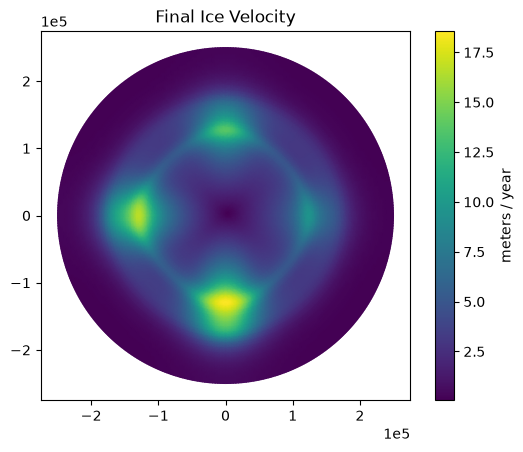

In [21]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(u, axes=axes)
fig.colorbar(colors, label="meters / year")
axes.set_title("Final Ice Velocity")

We can see the fastest ice is flowing where ice is constricted in valleys. Next, final ice surface elevation:

Text(0.5, 1.0, 'Final Ice \n Surface Elevation')

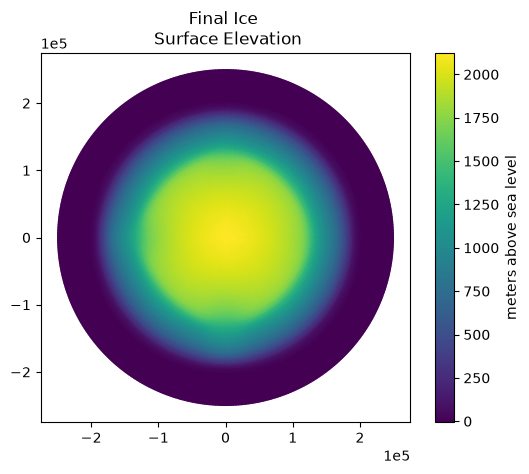

In [22]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(s, axes=axes)
fig.colorbar(colors, label="meters above sea level")
axes.set_title("Final Ice \n Surface Elevation")

Ice surface elevation visually appears to have only changed a little, so we can check current ice thickness compared to original ice thickness:

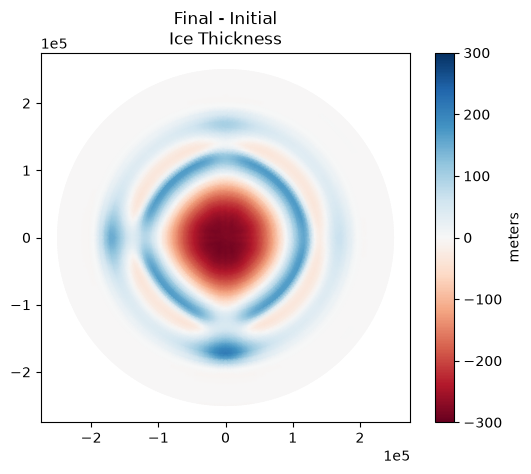

In [23]:
fig, axes = icepack.plot.subplots()
thickness_change = Function(Q).interpolate(h - h0)
colors = firedrake.tripcolor(
    thickness_change, vmin=-300, vmax=+300, axes=axes, cmap="RdBu"
)
fig.colorbar(colors, label="meters")
axes.set_title("Final - Initial\nIce Thickness");

We can also plot the last incremental change in thickness to see how close the ice sheet is to steady-state:

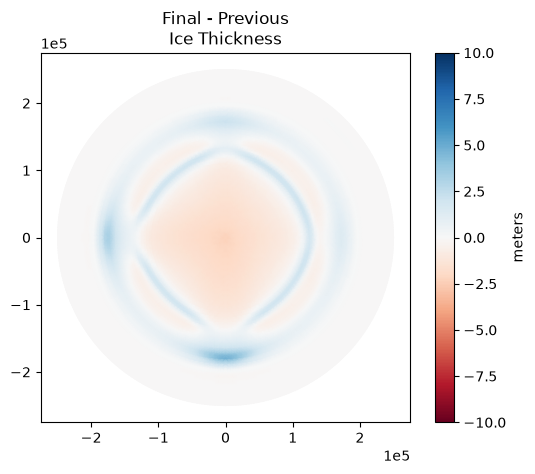

In [24]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(
    dh, vmin=-10, vmax=+10, axes=axes, cmap="RdBu"
)
fig.colorbar(colors, label="meters")
axes.set_title("Final - Previous\nIce Thickness");

Lastly, we can plot maximum change in thickness over time:


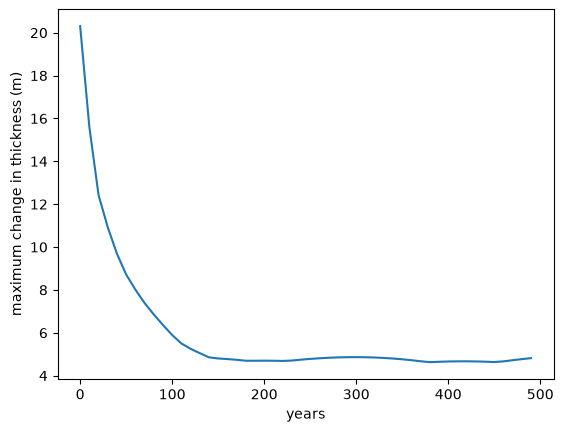

In [26]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(dt * np.arange(num_timesteps), dh_max)
plt.xlabel("years")
plt.ylabel("maximum change in thickness (m)")
axes.set_title("Max Change in Ice Thickness at Each Time Step");

Things to try playing around with: change mass balance parameters (typical Antarctic interior = 7 m/yr, SE Greenland = 0.5 - 1.5 m/yr), change bedrock topography (valley topography, height of ridge), change initial ice sheet geometry, change accumulation rate as a function of time (glacial cycles).